In [13]:
# Practia 10. Realizada por Angel Antolin

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_validate

from tqdm.notebook import tqdm

In [14]:
#Descargar dataset con los datos

X, Y = fetch_openml(data_id=1560, return_X_y=True, as_frame=False, parser='auto')

#Diccionario y tamaños de la capa oculta de 5 a 50 de 5 en 5
tabla = {}

tamanos_capa_oculta = range(5, 55, 5)

#Bluce principal con tqdm para ver el progreso
for nodos in tqdm(tamanos_capa_oculta, desc= "Progreso MLP"):

    #Aplicar el MLP y la validacion cruzada
    mlp = MLPClassifier(hidden_layer_sizes = (nodos,), max_iter = 2000, random_state = 42)

    resultados = cross_validate(mlp, X, Y, cv=10, return_train_score = True)

    #Guardar el dataframe
    df_resultados = pd.DataFrame({
                                'Entrena': resultados['train_score'],
                                'Verifica': resultados['test_score'],
                                'T. Ejecucion': resultados['fit_time'] + resultados['score_time']
    })

    #Guardar en el diccionario
    clave = f'hidden_{nodos}'

    tabla[clave] = df_resultados

#Mostramos el resultado de ejemplo pedido en el enunciado
print("\nEjemplo de tabla para 15 neuronas en la capa oculta:")
print(tabla['hidden_15'])

Progreso MLP:   0%|          | 0/10 [00:00<?, ?it/s]


Ejemplo de tabla para 15 neuronas en la capa oculta:
    Entrena  Verifica  T. Ejecucion
0  0.980136  0.953052      1.065042
1  0.972818  0.971831      0.743216
2  0.983795  0.938967      0.835062
3  0.977522  0.948357      0.626121
4  0.956613  0.920188      0.760980
5  0.978568  0.995305      0.697065
6  0.977534  0.957547      0.596361
7  0.978579  0.948113      0.833513
8  0.965517  0.981132      0.642781
9  0.982236  0.797170      0.953325


--- Tabla Resumen ---


,Entrena,Verifica,T. Ejecucion
N_ocultas,,,
5,0.895322,0.879073,1.792962
10,0.951763,0.928047,1.947828
15,0.975332,0.941166,0.775347
20,0.959600,0.928937,0.738955
25,0.967282,0.926597,0.675595
30,0.958347,0.905361,0.735479
35,0.960752,0.905364,0.759898
40,0.926413,0.887997,0.347258
45,0.928500,0.900252,0.530812




Mejor tamaño de capa oculta en Aprendizaje (Entrena): 15 nodos
Mejor tamaño de capa oculta en Test (Verifica): 15 nodos
Menor tiempo de ejecución requerido: 40 nodos


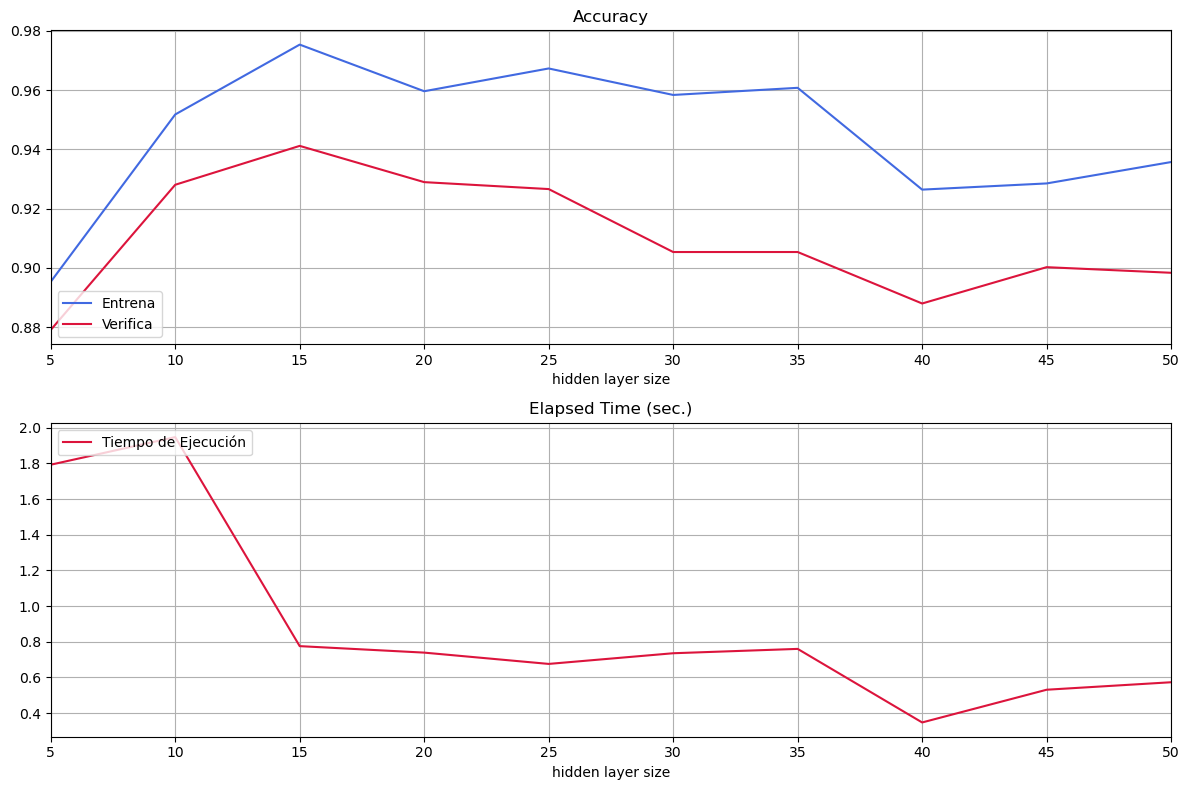

In [20]:
#tabla resumen
tabla_resumen = []

#Bucle que recorre el diccionario
for clave, df_resultados in tabla.items():

    #Sacar el numero de nodos y la media de resultados
    num_nodos = int(clave.split('_')[1])

    medias = df_resultados.mean()

    tabla_resumen.append({
        'N_ocultas': num_nodos,
        'Entrena': medias['Entrena'],
        'Verifica': medias['Verifica'],
        'T. Ejecucion': medias['T. Ejecucion']
    })

#Crear la tabla y mostrarla
df_resumen = pd.DataFrame(tabla_resumen).set_index('N_ocultas')

df_resumen.sort_index(inplace = True)

print("--- Tabla Resumen ---")
display(df_resumen)
print("\n")


# Extracción automática de los mejores resultados
mejor_entrena = df_resumen['Entrena'].idxmax()
mejor_verifica = df_resumen['Verifica'].idxmax()
mejor_tiempo = df_resumen['T. Ejecucion'].idxmin()

print(f"Mejor tamaño de capa oculta en Aprendizaje (Entrena): {mejor_entrena} nodos")
print(f"Mejor tamaño de capa oculta en Test (Verifica): {mejor_verifica} nodos")
print(f"Menor tiempo de ejecución requerido: {mejor_tiempo} nodos")


# Representación gráfica
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

# --- Gráfica Superior: Accuracy ---
ax1.plot(df_resumen.index, df_resumen['Entrena'], color='royalblue', label='Entrena')
ax1.plot(df_resumen.index, df_resumen['Verifica'], color='crimson', label='Verifica')
ax1.set_title('Accuracy')
ax1.set_xlabel('hidden layer size')
ax1.set_xlim(5, 50) 
ax1.grid(True)
ax1.legend(loc='lower left')

# --- Gráfica Inferior: Elapsed Time ---
ax2.plot(df_resumen.index, df_resumen['T. Ejecucion'], color='crimson', label='Tiempo de Ejecución')
ax2.set_title('Elapsed Time (sec.)')
ax2.set_xlabel('hidden layer size')
ax2.set_xlim(5, 50)
ax2.grid(True)
ax2.legend(loc='upper left')


plt.tight_layout()
plt.show()
    